## January 2026 
In this file I will test the output of the new version of CosmoTherm FH. <br>
I will look at the anisotropic spectral distortions sourced by photon to dark photon conversion in absence of anisotropic heating, using the transfer functions. <br>


In [40]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import tol_colors as tc

import tools
import my_plot as mplt

In [41]:
def extract_custom_state_from_files(folder_path, ell, pattern="custom_state_kv_001_yn_aniso_system-all_wG.dat_ymax15_lmax25_adiabatic.dat"):
    """Extract custom transfer function data from files in a folder """
    folder = Path(folder_path) / "batch" / "FH" 
    file_path = next(folder.glob(pattern))
    
    theta = [[] for _ in range(ell+1)]
    mu = [[] for _ in range(ell+1)]
    y = [[] for _ in range(ell+1)]
    z = []
    
    data = np.loadtxt(file_path, comments='#')  
    z.extend(data[:, 0])  # First column is redshift
    for i in range(ell+1):
        theta[i].extend(data[:, 1+i*(ell)])   # All theta values from column 1 and multiples of it
        print( " theta ", i, "comes from column ", 1+i*(ell))
        y[i].extend(data[:, 2+i*(ell)])       # All y values from column 2 and multiples of it
        print( " y ", i, "comes from column ", 2+i*(ell))
        mu[i].extend(data[:, 3+i*(ell)])  # All mu values from column 3 and multiples of it
        print( " mu ", i, "comes from column ", 3+i*(ell))
    
    return z, np.array(theta), np.array(y), np.array(mu)

In [42]:
def extract_state_scattering_basis(folder_path, ell, ell_max, k, basis="scattering"):
    """Extract scattering basis transfer function data from files in a folder """
    folder = Path(folder_path)
    file_path = []
    file_path2 = []
    # Collect multipole files (0,1,2,...)
    for i in range(ell+1):
        file_path.append(next(folder.glob(f"full_state_kv_{k}.dat_ymax15_lmax{ell_max}_adiabatic_scattering-basis_{i}.dat")))
        # theta values always come from the computational basis for the scattering
        file_path2.append(next(folder.glob(f"full_state_kv_{k}.dat_ymax15_lmax{ell_max}_adiabatic_computation-basis_{i}.dat"))) 
    # Collect background file
    bg_file = next(folder.glob(f"full_state_kv_{k}.dat_ymax15_lmax{ell_max}_adiabatic_scattering-basis_bg.dat"))
    bg_file2 = next(folder.glob(f"full_state_kv_{k}.dat_ymax15_lmax{ell_max}_adiabatic.dat"))

    theta = [[] for _ in range(ell+3)]
    mu = [[] for _ in range(ell+2)]
    y = [[] for _ in range(ell+2)]
    a = []

    # Read header to find theta_corr_0 column (format: "name [col_num]")
    with open(bg_file2, 'r') as f:
        header_line = f.readline().strip('# \n')
        header = header_line.split()
    # Find column index for theta_corr_0: look for "theta_corr_0", then get number from next element "[N]"
    idx = header.index("theta_corr_0")
    theta_corr_col = int(header[idx + 1].strip('[]')) - 1  # Convert to 0-indexed

    # First: background
    data_bg = np.loadtxt(bg_file, comments='#')
    data_theta_bg = np.loadtxt(bg_file2, comments='#')
    
    a.extend(data_bg[:, 0])  # First column is redshift (only read once)
    theta[0].extend(data_theta_bg[:, 1])
    y[0].extend(data_bg[:, 2])
    mu[0].extend(data_bg[:, 9])

    # Then: multipoles
    for i in range(ell+1):
        data = np.loadtxt(file_path[i], comments='#')
        data_theta = np.loadtxt(file_path2[i], comments='#')
        theta[i+1].extend(data_theta[:, 1])
        y[i+1].extend(data[:, 2])
        mu[i+1].extend(data[:, 9])
    
    # Load corrections to the monopole from the background file (dynamically found column)
    theta[-1].extend(data_theta_bg[:, theta_corr_col])

    return a, np.array(theta), np.array(y), np.array(mu)

In [43]:
ell = 0
kv_values = [ "00001", "00002", "00003"]

In [44]:

theta = []
y = []
mu = []
a = []




for kv in kv_values:
    zt, th, yy, m = extract_state_scattering_basis("../Data/Dark-photons/output_dp_tfph/outputs-dp1.0_ph/batch/FH/yn_T_aniso_system", ell, 150, kv )
    #zt, th, yy, m = extract_state_scattering_basis("../Data/Dark-photons/dp-aniso1.0/", ell, 50, kv )
        
    theta.append(th)
    y.append(yy)
    mu.append(m)
    a.append(zt)

In [45]:
kv_values_Mpc = [1,0.1,0.01]


In [46]:
theta[0][-1]/(theta[0][1]*3)

array([ 1.70735738e-06,  1.70735711e-06,  1.70735684e-06, ...,
       -1.11103078e-06, -1.11103476e-06, -1.11103476e-06], shape=(5000,))

In [47]:
#colors = mplt.set_colors(4, palette="dark_photons")
colors = mplt.set_colors(4, palette="colorblind")


def plot_transfer_functions(a, theta, y, mu, colors, zcon, m_dp):
    fig, ax1 = plt.subplots(3, 3, figsize=mplt.set_size(mplt.width*3, 1, (3,3)), sharey='row')
    fig.subplots_adjust(hspace=0, wspace=0)

    # Loop over columns (kv = 001, 002, 003) and rows (ell = 1, 2, 3)
    theta_bar = 1.7*1e-6
    for col in range(len(kv_values_Mpc)):  # columns for different kv values
        ax1[0, col].plot(a[col], 4.0*theta[col][0]*1e6, label="$4\\theta^{(0)}$", color=colors[0],    linestyle="-")
        ax1[0, col].plot(a[col], 4.0*y[col][0]*1e6, label="$4y^{(0)}$", color=colors[1],    linestyle="-")
        ax1[0, col].plot(a[col], 1/1.401*mu[col][0]*1e6, label="$0.714\\mu^{(0)}$", color=colors[2],    linestyle="-")
        for ell_idx in range(1, ell+2):  # ell multipoles 1, 2, 3
            ax1[1, col].plot(a[col], 4.0*theta[col][ell_idx], label=f"$4\\theta^{{(1)}}_{ell_idx-1}$", color=colors[0],    linestyle="-")
            #ax1[1,col].plot(a[col], 4.0*theta[col][-1]*1e5, label="$4 \\,\\delta \\theta^{{(1)}} \\times 10^5$", color=colors[1],    linestyle="-")
            #ax1[1,col].plot(a[col], 4.0/3.0*theta[col][-1]/theta_bar, label="$\\frac{4}{3} \\frac{\\delta \\theta^{(1)}}{\\bar{\\theta}}$", color=colors[1],    linestyle="-")

            ax1[2,col].plot(a[col], 4*theta[col][-1]*1e5, label="$4 \\,\\delta \\theta^{{(1)}}$", color=colors[0],    linestyle="-")
            ax1[2, col].plot(a[col], 4*y[col][ell_idx]*1e5, label=f"$4y^{{(1)}}_{ell_idx-1}$", color=colors[1],    linestyle="-")
            ax1[2, col].plot(a[col], 1/1.401*mu[col][ell_idx]*1e5, label=f"$0.714\\mu^{{(1)}}_{ell_idx-1}$", color=colors[2],    linestyle="-")
        
        

        ax1[0, col].set_title(f"k = {kv_values_Mpc[col]}" "${\\rm Mpc^{-1}}$")

    # Set labels for left column
    ax1[0, 0].set_ylabel("Transfer functions $\\times 10^6$")
    ax1[1, 0].set_ylabel("Transfer functions")
    ax1[2, 0].set_ylabel("Transfer functions $\\times 10^5$")

    # Set x-labels for bottom row only
    for col in range(3):
        ax1[2, col].set_xlabel("a")

    # Remove x tick labels for top two rows
    for row in range(2):
        for col in range(3):
            ax1[row, col].tick_params(labelbottom=False)

    # Remove y tick labels for middle and right columns
    for row in range(3):
        for col in range(1, 3):
            ax1[row, col].tick_params(labelleft=False)

    # Apply formatting to all subplots
    for ax in ax1.flat:
        ax.set_xscale('log')
        ax.minorticks_on()
        ax.tick_params(direction='in', right=True, top=True)
        ax.tick_params(labelsize=12)
        ax.tick_params(direction='in', which='minor', length=5, bottom=True, top=True, left=True, right=True)
        ax.tick_params(direction='in', which='major', length=10, bottom=True, top=True, left=True, right=True)
        ax.grid(True, which='both', linestyle='--', linewidth=0.3, alpha=0.7)

        ax.axvline(x= 1 / (1+zcon), color='gray', linestyle='dashed', linewidth=1)


    # Add legend to first column subplots
    ax1[0, 0].legend()
    ax1[1, 0].legend()
    ax1[2, 0].legend(loc='upper right')

    # Dynamically place annotation using axis proportions
    xlim = ax1[2, 0].get_xlim()
    ylim = ax1[2, 0].get_ylim()
    x_annot = xlim[0] + 0.005 * (xlim[1] - xlim[0])  # 5% from left
    y_annot = ylim[0] + 0.1 * (ylim[1] - ylim[0])   # 10% from bottom
    ax1[2, 0].annotate(f"$m_{{\\rm dp}}$ = {tools.sci_notation(m_dp)}", xy=(x_annot, y_annot), fontsize=12)

    plt.tight_layout() 
    plt.savefig(f'outputs/transfer_functions_ph_zcon{np.log10(zcon/5):.0f}.pdf', dpi=300, bbox_inches="tight")
    plt.show()

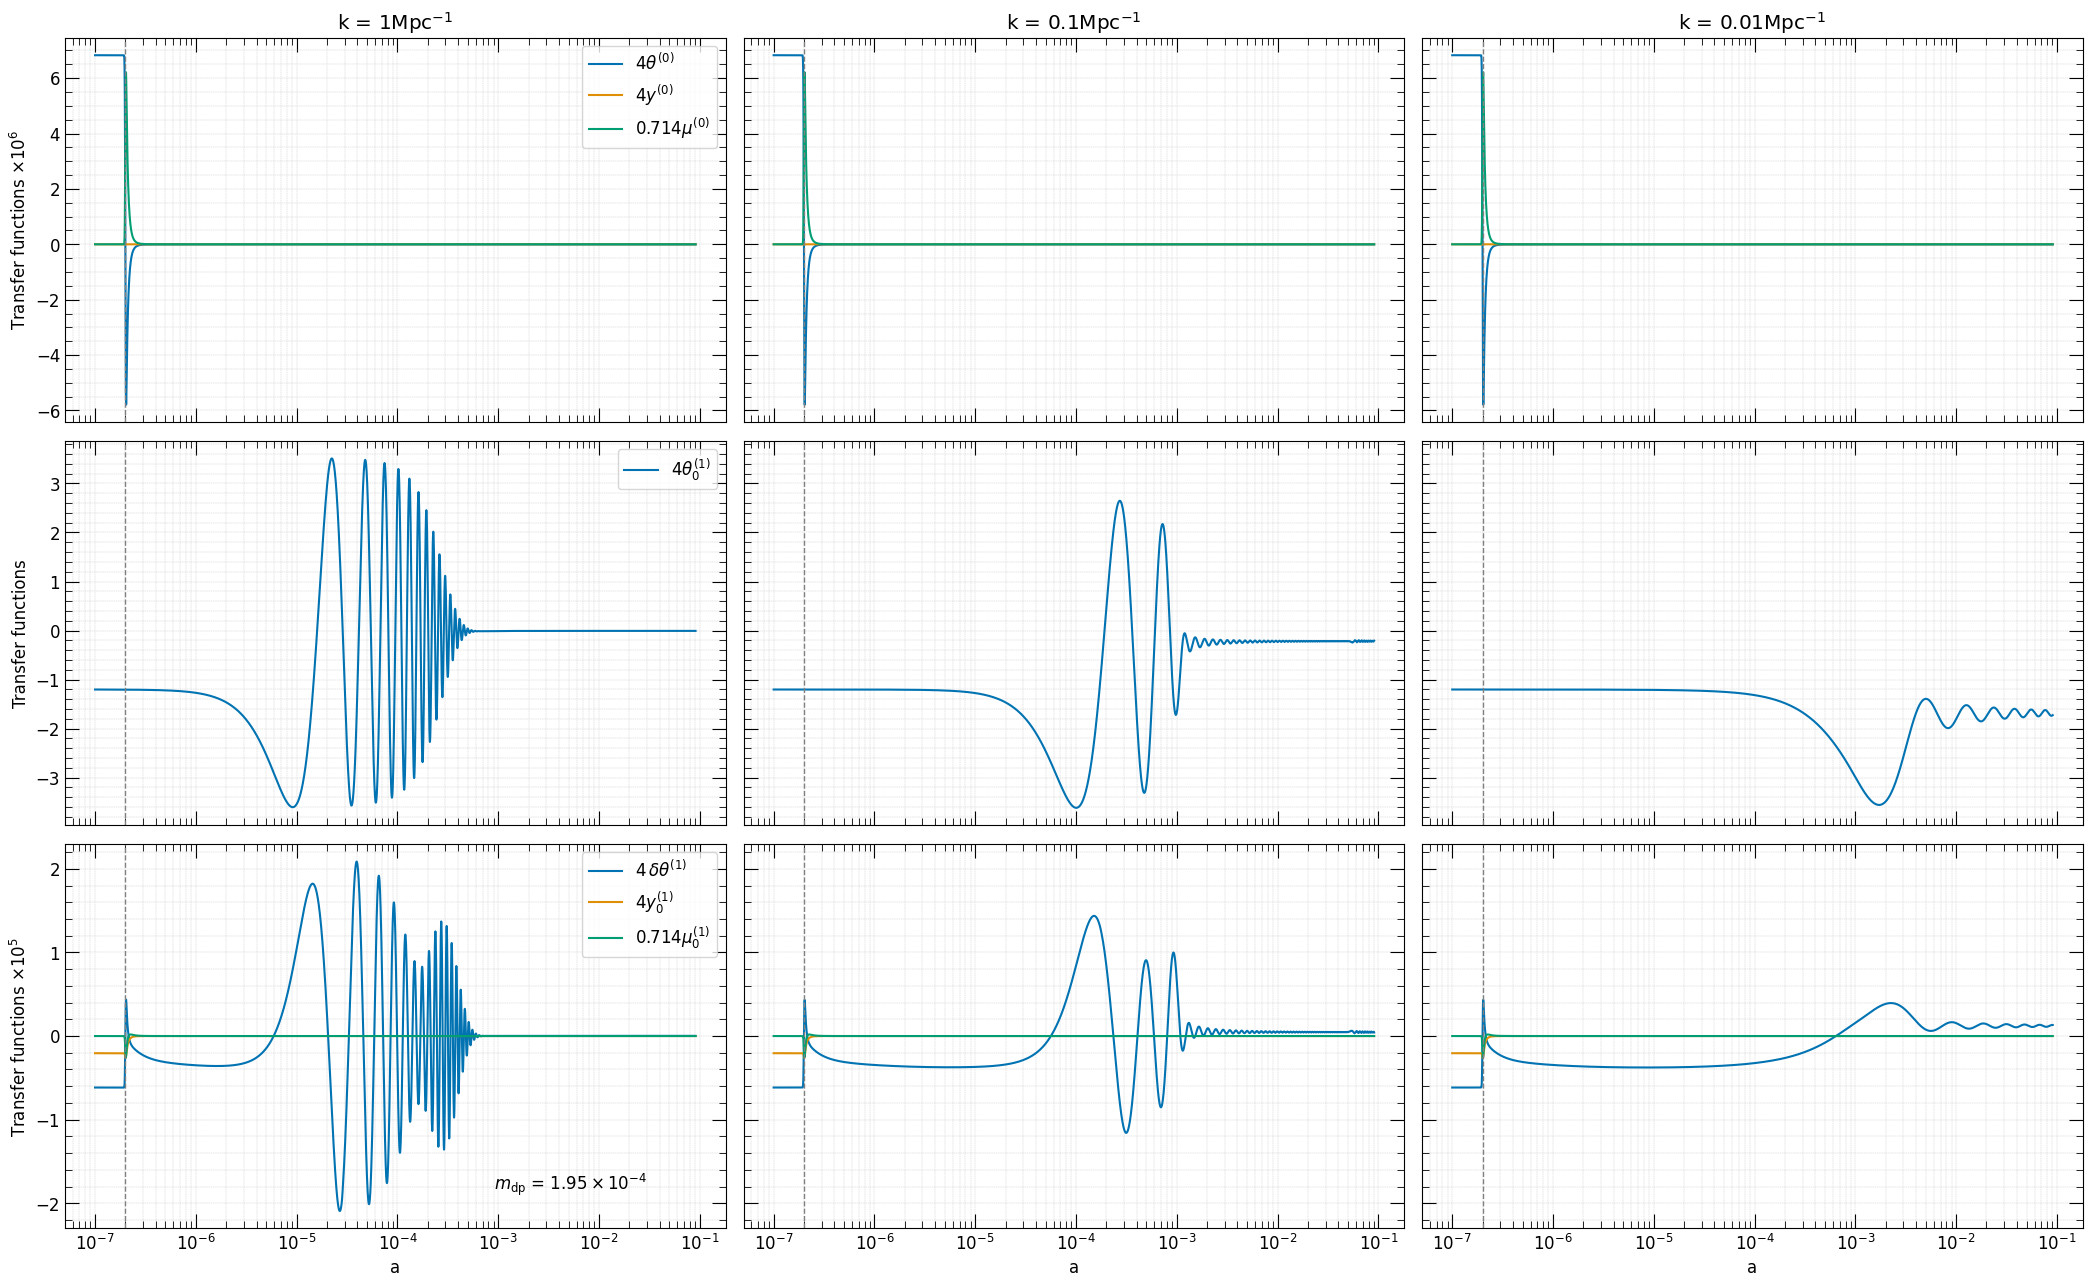

In [48]:


zcon = 5.0e6 
m_dp = 0.000195304 
# Plot Analytical Spectra

plot_transfer_functions(a, theta, y, mu, colors, zcon, m_dp)


In [49]:
theta_1 = []
y_1 = []
mu_1 = []
a_1 = []

for kv in kv_values:
   
    zt, th, yy, m = extract_state_scattering_basis("../Data/Dark-photons/output_dp_tfph/outputs-dp1.1_ph/batch/FH/yn_T_aniso_system", ell, 150, kv )
    #zt, th, yy, m = extract_state_scattering_basis("../Data/Dark-photons/dp-aniso1.1/", ell, kv )
    
    theta_1.append(th)
    y_1.append(yy)
    mu_1.append(m)
    a_1.append(zt)

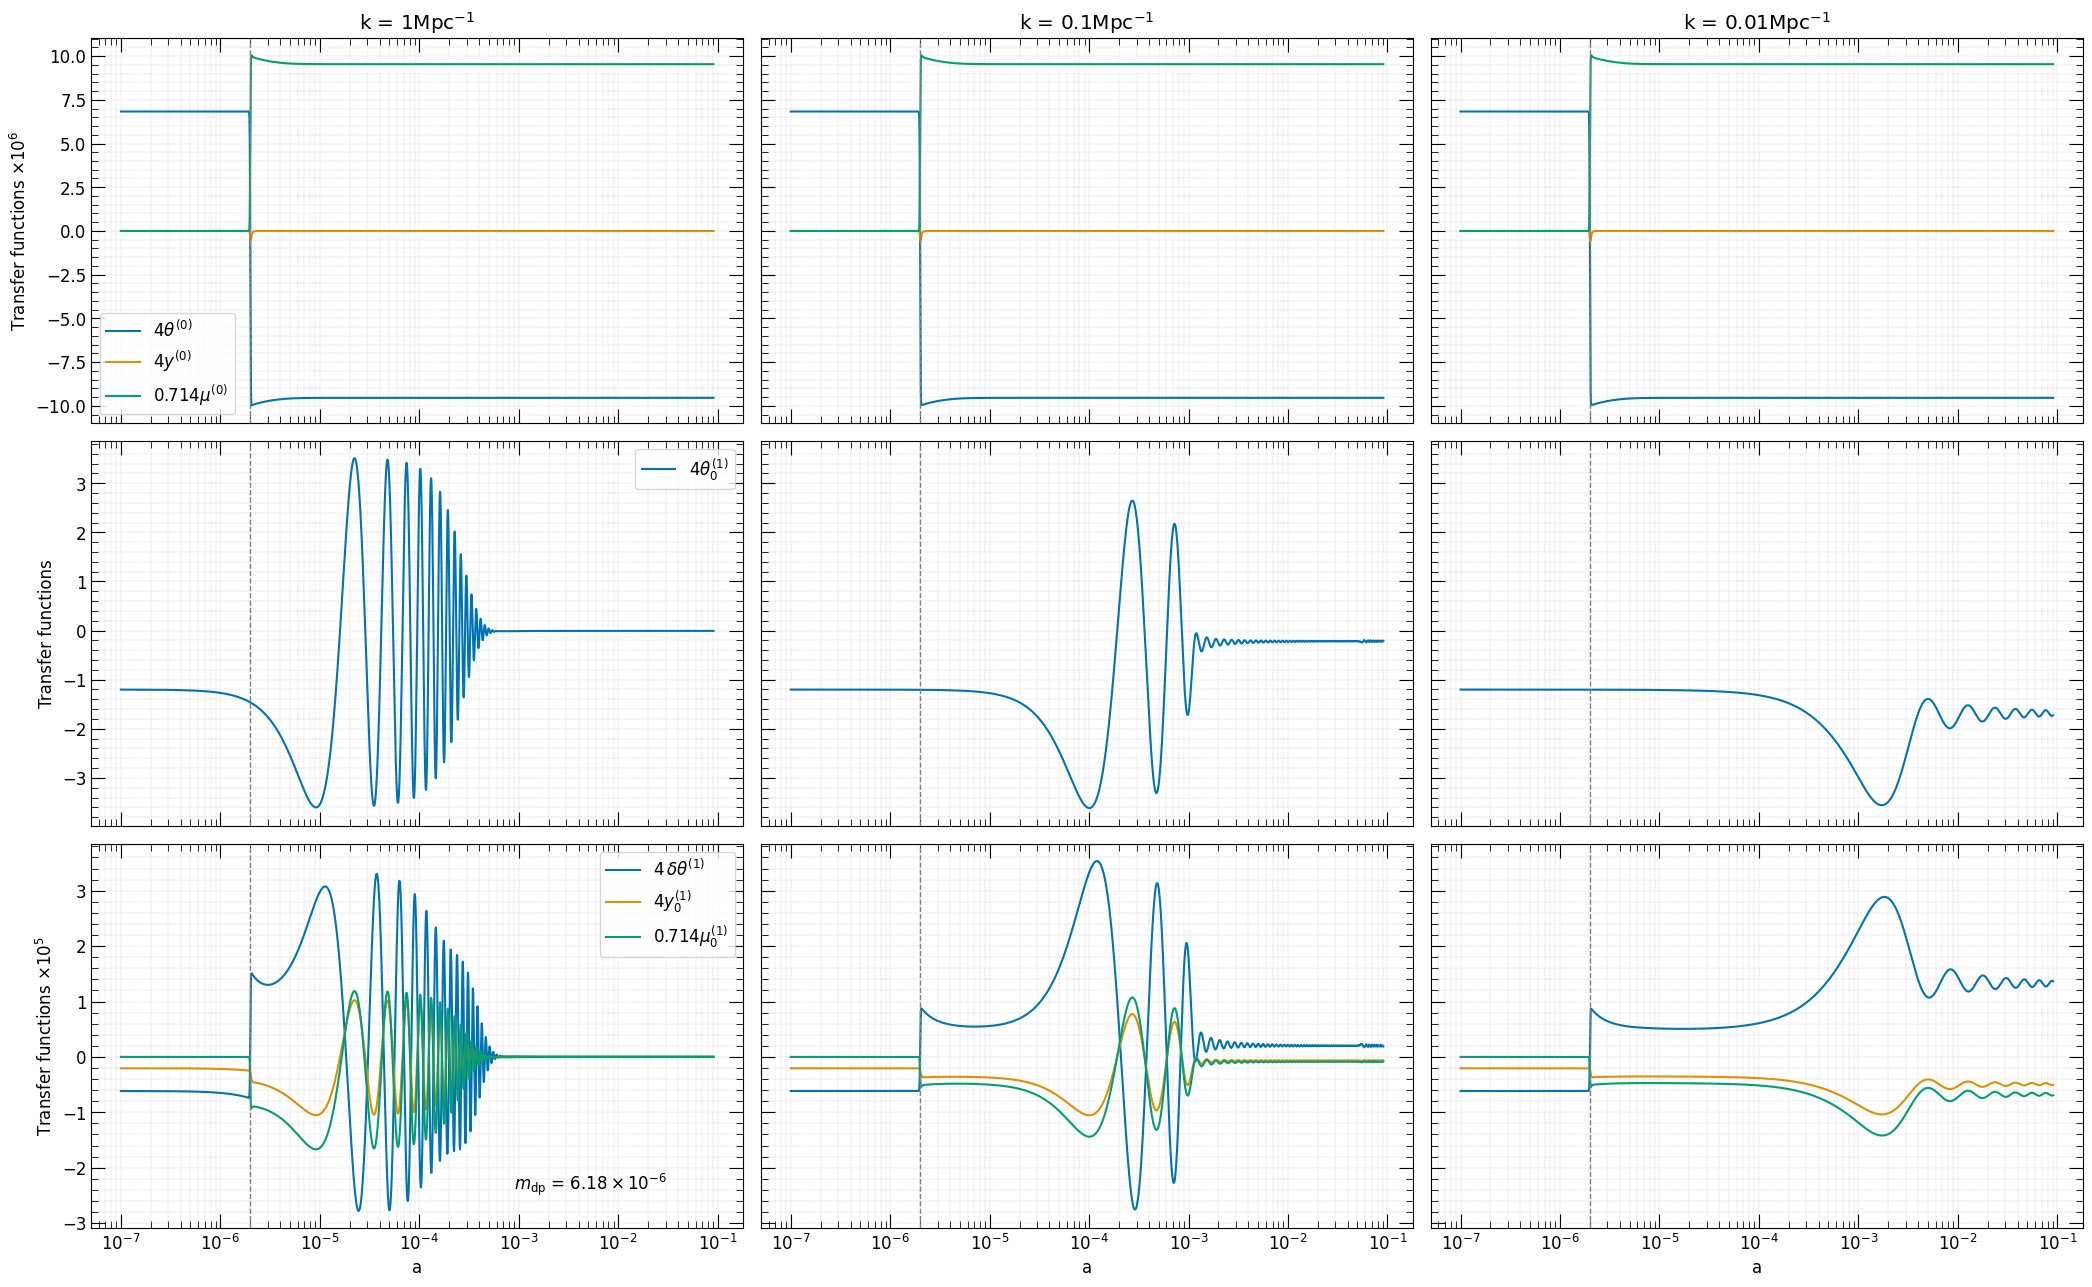

In [50]:
zcon = 5.0e5 
m_dp = 6.17608e-06

plot_transfer_functions(a_1, theta_1, y_1, mu_1, colors, zcon, m_dp)

In [51]:
theta_2 = []
y_2 = []
mu_2 = []
a_2 = []

for kv in kv_values:
    #zt, th, yy, m = extract_state_scattering_basis("../Data/Dark-photons/dp-aniso1.2/", ell, kv )
    zt, th, yy, m = extract_state_scattering_basis("../Data/Dark-photons/output_dp_tfph/outputs-dp1.2_ph/batch/FH/yn_T_aniso_system/", ell, 150, kv )
    
    theta_2.append(th)
    y_2.append(yy)
    mu_2.append(m)
    a_2.append(zt)

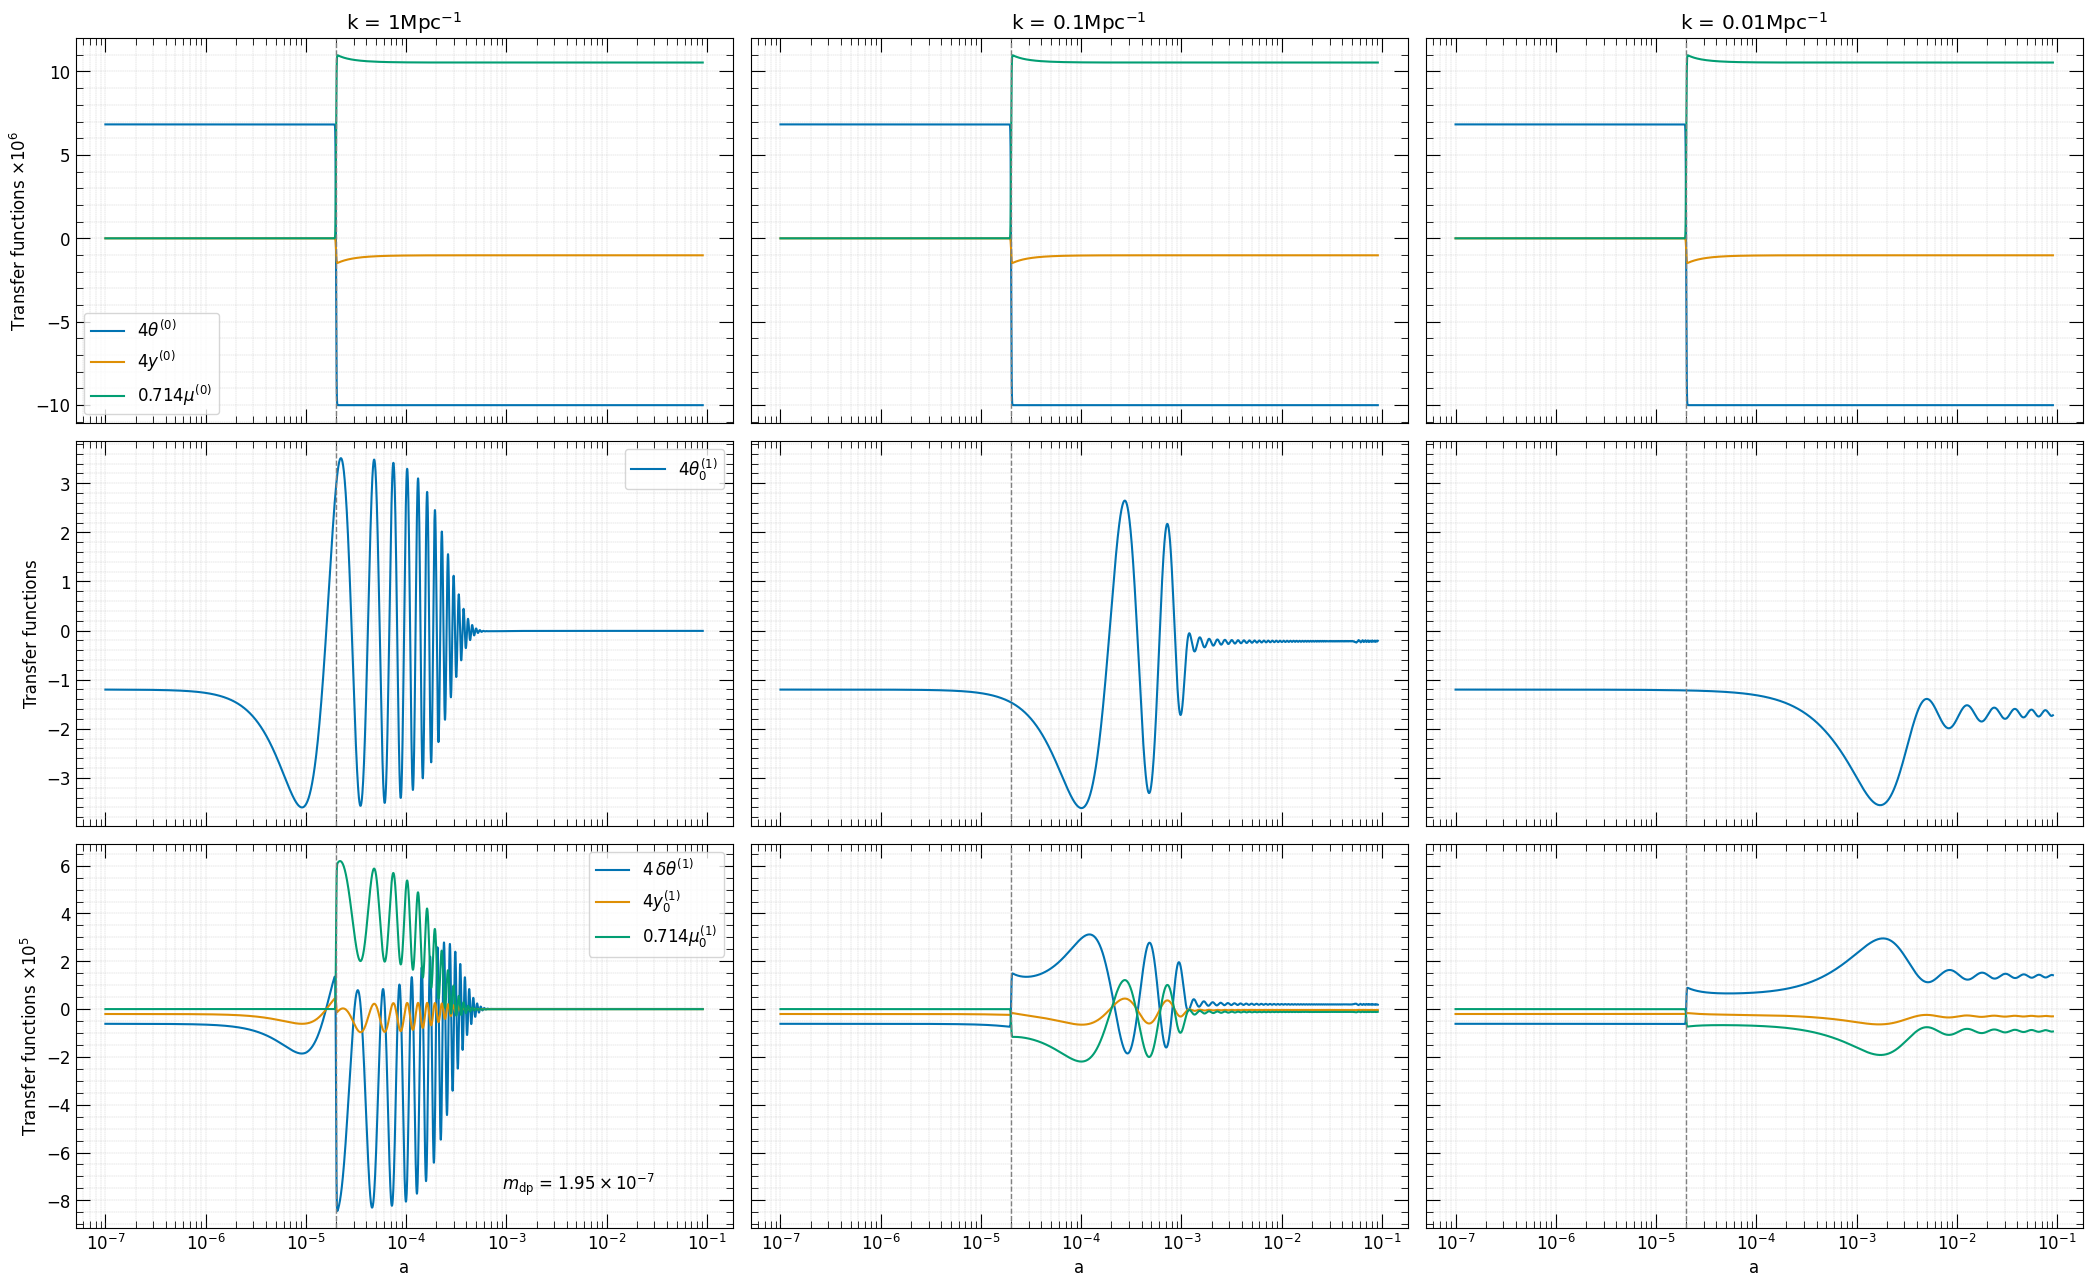

In [52]:
zcon = 5.0e4 
m_dp = 1.9531e-07

plot_transfer_functions(a_2, theta_2, y_2, mu_2, colors, zcon, m_dp)

In [53]:
kv_values = [ "001", "002", "003"]

theta_3 = []
y_3 = []
mu_3 = []
a_3 = []

for kv in kv_values:
    #zt, th, yy, m = extract_state_scattering_basis("../Data/Dark-photons/dp-aniso1.3/", ell, kv )
    zt, th, yy, m = extract_state_scattering_basis("../Data/Dark-photons/output_dp_tfph/outputs-dp1.3_ph/batch/FH/yn_T_aniso_system", ell, 150, kv )
    
    theta_3.append(th)
    y_3.append(yy)
    mu_3.append(m)
    a_3.append(zt)

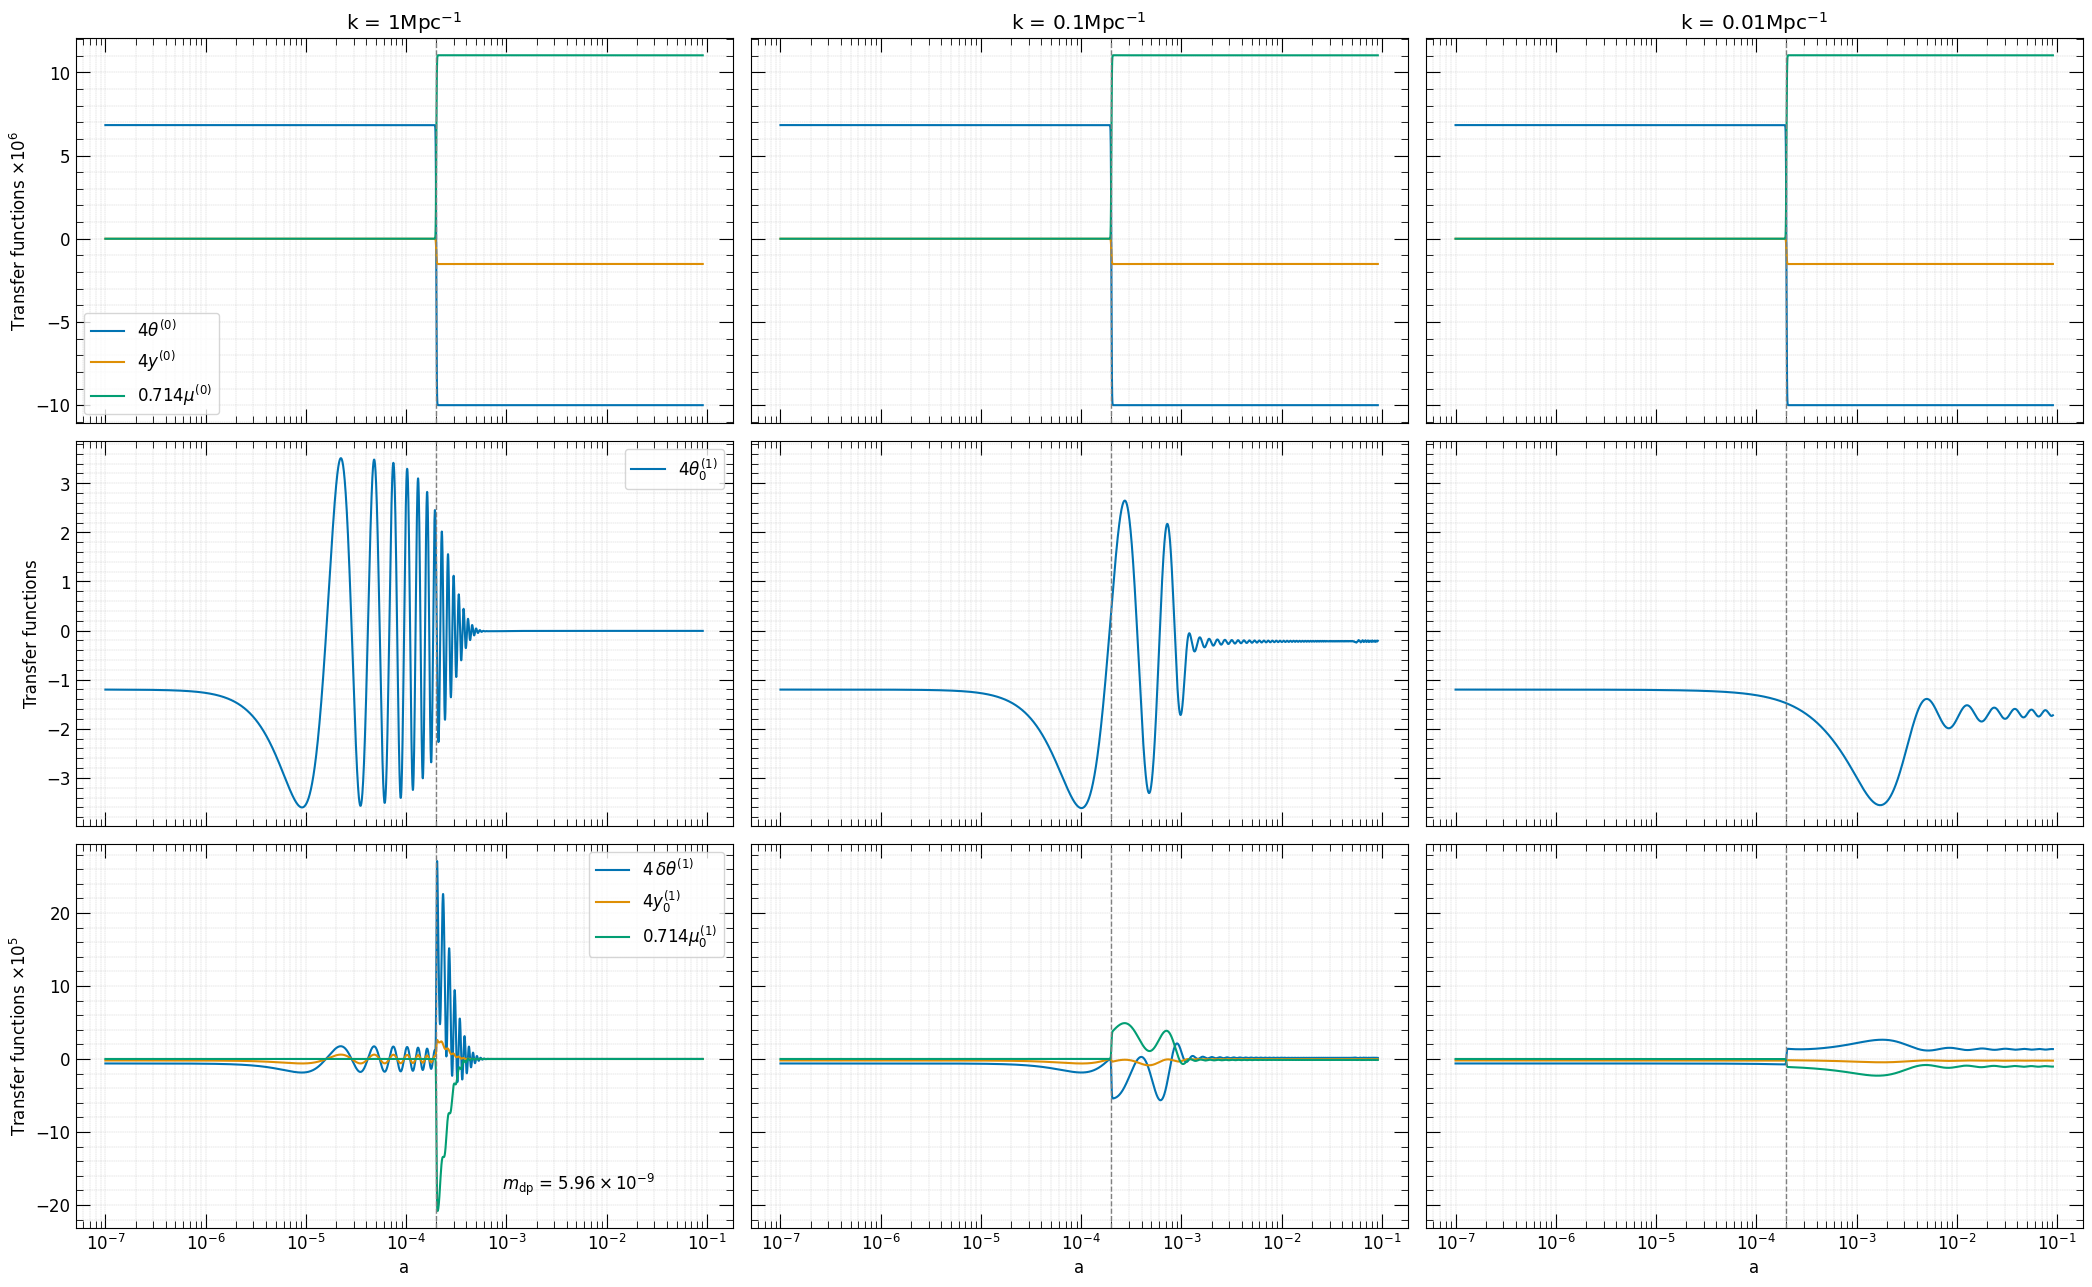

In [55]:
zcon = 5.0e3 
m_dp = 5.9625e-09

plot_transfer_functions(a_3, theta_3, y_3, mu_3, colors, zcon, m_dp)